# Clustering – Assignment Questions & Answers
**Part 1:** Theoretical questions (1–20) &nbsp;|&nbsp; **Part 2:** Practical questions (21–48)

# Part 1 – Theoretical Questions

### Q1. What is unsupervised learning in the context of machine learning?

**Answer:**

Unsupervised learning trains models on **unlabeled data** (no target variable). The algorithm discovers hidden structure on its own, e.g. groups (clustering), lower-dimensional representations (PCA, t-SNE), associations or anomalies. Examples: K-Means, DBSCAN, hierarchical clustering, PCA.

### Q2. How does K-Means clustering algorithm work?

**Answer:**

1. Choose the number of clusters **k**.
2. Initialise k centroids (randomly or with K-Means++).
3. **Assign** every point to its nearest centroid (Euclidean distance).
4. **Update** each centroid as the mean of the points assigned to it.
5. Repeat steps 3–4 until assignments stop changing (or max iterations reached).

It minimises the within-cluster sum of squares (inertia).

### Q3. Explain the concept of a dendrogram in hierarchical clustering.

**Answer:**

A dendrogram is a **tree diagram** showing the order in which clusters are merged (agglomerative) or split (divisive). Leaves are individual samples; the height of each merge is the distance/dissimilarity at which two clusters join. Cutting the tree with a horizontal line at a chosen height gives a flat clustering, so it helps decide the number of clusters (look for the longest vertical gaps).

### Q4. What is the main difference between K-Means and Hierarchical Clustering?

**Answer:**

| | K-Means | Hierarchical |
|---|---|---|
| Number of clusters | Must be specified in advance | Not needed up front; choose by cutting the dendrogram |
| Structure | Flat partition | Nested tree of clusters |
| Complexity | ~O(n·k·i), scales to large data | O(n²) memory / O(n²–n³) time, small–medium data |
| Determinism | Depends on initialisation | Deterministic |
| Shape | Prefers spherical clusters | Depends on linkage |

### Q5. What are the advantages of DBSCAN over K-Means?

**Answer:**

- No need to specify the number of clusters
- Finds **arbitrarily shaped** clusters (moons, circles)
- Explicitly detects **noise/outliers**
- Robust to outliers (they do not distort centroids)
- Not dependent on random initialisation

### Q6. When would you use Silhouette Score in clustering?

**Answer:**

To **evaluate cluster quality without ground-truth labels** and to choose the best number of clusters (k) or parameters (e.g. eps). It measures how close a point is to its own cluster compared with the nearest other cluster; values lie in [-1, 1] and higher is better.

### Q7. What are the limitations of Hierarchical Clustering?

**Answer:**

- Poor scalability (O(n²) memory and time)
- Merges/splits are **irreversible** (greedy), so early mistakes persist
- Sensitive to noise, outliers and the choice of linkage/distance
- Dendrograms become hard to read for large datasets
- Needs a cut-off decision to obtain final clusters

### Q8. Why is feature scaling important in clustering algorithms like K-Means?

**Answer:**

K-Means, DBSCAN and hierarchical clustering are **distance-based**. Features with larger numeric ranges dominate the distance and bias the clusters. Standardisation (zero mean, unit variance) or Min-Max scaling puts all features on a comparable scale so each contributes fairly.

### Q9. How does DBSCAN identify noise points?

**Answer:**

A point is **noise** if it is neither a core point (fewer than `min_samples` points within radius `eps`) nor a border point (not within `eps` of any core point). Such points are given the label **-1**.

### Q10. Define inertia in the context of K-Means.

**Answer:**

Inertia is the **sum of squared distances between each sample and its assigned cluster centroid** (within-cluster sum of squares, WCSS): Σ ‖x − μ_c‖². Lower inertia means more compact clusters. It always decreases as k grows, so it cannot be used alone to choose k.

### Q11. What is the elbow method in K-Means clustering?

**Answer:**

Run K-Means for a range of k, plot **inertia vs k**, and pick the k at the "elbow" – the point after which adding more clusters yields only a small reduction in inertia.

### Q12. Describe the concept of "density" in DBSCAN.

**Answer:**

Density is the number of points within a neighbourhood of radius **eps** around a point. A region is *dense* if it contains at least **min_samples** points. Clusters are maximal sets of density-connected points; low-density regions separate clusters and contain noise.

### Q13. Can hierarchical clustering be used on categorical data?

**Answer:**

Yes, provided a suitable **dissimilarity measure** is used instead of Euclidean distance – e.g. Hamming/Jaccard distance, Gower distance (mixed data) – with a precomputed distance matrix and average/complete linkage (Ward requires Euclidean). Alternatively use one-hot encoding or K-Modes.

### Q14. What does a negative Silhouette Score indicate?

**Answer:**

The sample is probably **assigned to the wrong cluster** – it is on average closer to points of a neighbouring cluster than to its own. An overall negative score suggests overlapping or badly chosen clusters.

### Q15. Explain the term "linkage criteria" in hierarchical clustering.

**Answer:**

Linkage defines how the distance **between two clusters** is computed when merging:
- **Single** – minimum distance between points (chaining effect)
- **Complete** – maximum distance (compact clusters)
- **Average** – mean pairwise distance
- **Ward** – merge that minimally increases total within-cluster variance

### Q16. Why might K-Means clustering perform poorly on data with varying cluster sizes or densities?

**Answer:**

K-Means assumes clusters are **roughly spherical, equally sized and with similar density**, because it assigns points to the nearest centroid with equal weight. Large/sparse clusters get split, small/dense ones get merged, and boundaries are placed midway between centroids regardless of spread. It is also sensitive to outliers.

### Q17. What are the core parameters in DBSCAN, and how do they influence clustering?

**Answer:**

- **eps**: neighbourhood radius. Too small → many noise points and fragmented clusters; too large → clusters merge.
- **min_samples**: minimum points to form a dense region/core point. Larger values → stricter density, more noise, fewer clusters.

A k-distance plot is commonly used to choose eps.

### Q18. How does K-Means++ improve upon standard K-Means initialization?

**Answer:**

K-Means++ picks the first centroid at random, then chooses each next centroid with probability **proportional to the squared distance** from the nearest chosen centroid. Centroids are therefore spread out, leading to faster convergence, better final inertia, and fewer bad local minima than purely random initialisation.

### Q19. What is agglomerative clustering?

**Answer:**

A **bottom-up hierarchical** method: every sample starts as its own cluster and the two closest clusters (per the linkage criterion) are merged repeatedly until one cluster (or the desired number of clusters) remains.

### Q20. What makes Silhouette Score a better metric than just inertia for model evaluation?

**Answer:**

Inertia only measures **compactness**, always falls as k increases and is not bounded. Silhouette considers both **cohesion and separation**, is bounded in [-1, 1], can be computed per sample, and has a clear maximum at a good k – so it is better for comparing models with different k and for detecting misassigned points.

# Part 2 – Practical Questions

### Common setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import (make_blobs, make_moons, make_circles, load_iris,
                              load_wine, load_breast_cancer, load_digits)
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, silhouette_samples
from scipy.cluster.hierarchy import linkage, dendrogram

RS = 42

### Q21. Generate synthetic data with 4 centers using make_blobs and apply K-Means clustering. Visualize using a scatter plot.

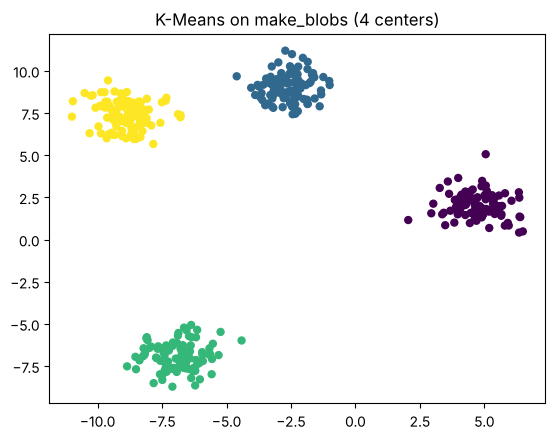

In [2]:
X, _ = make_blobs(n_samples=400, centers=4, cluster_std=0.8, random_state=RS)
labels = KMeans(n_clusters=4, n_init=10, random_state=RS).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=25)
plt.title("K-Means on make_blobs (4 centers)"); plt.show()

### Q22. Load the Iris dataset and use Agglomerative Clustering to group the data into 3 clusters. Display the first 10 predicted labels.

In [3]:
Xi = load_iris().data
agg = AgglomerativeClustering(n_clusters=3).fit(Xi)
print("First 10 predicted labels:", agg.labels_[:10])

First 10 predicted labels: [1 1 1 1 1 1 1 1 1 1]


### Q23. Generate synthetic data using make_moons and apply DBSCAN. Highlight outliers in the plot.

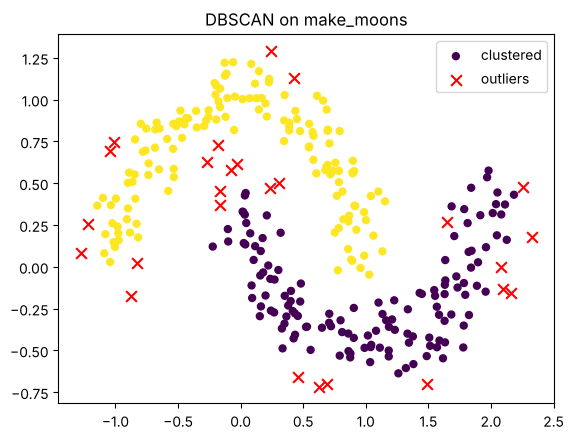

Outliers: 26


In [4]:
Xm, _ = make_moons(n_samples=300, noise=0.12, random_state=RS)
lab = DBSCAN(eps=0.15, min_samples=5).fit_predict(Xm)
core = lab != -1
plt.scatter(Xm[core, 0], Xm[core, 1], c=lab[core], cmap="viridis", s=25, label="clustered")
plt.scatter(Xm[~core, 0], Xm[~core, 1], c="red", marker="x", s=60, label="outliers")
plt.title("DBSCAN on make_moons"); plt.legend(); plt.show()
print("Outliers:", (~core).sum())

### Q24. Load the Wine dataset and apply K-Means clustering after standardizing the features. Print the size of each cluster.

In [5]:
Xw = StandardScaler().fit_transform(load_wine().data)
lw = KMeans(n_clusters=3, n_init=10, random_state=RS).fit_predict(Xw)
for c, s in enumerate(np.bincount(lw)):
    print(f"Cluster {c}: {s} samples")

Cluster 0: 65 samples
Cluster 1: 51 samples
Cluster 2: 62 samples


### Q25. Use make_circles to generate synthetic data and cluster it using DBSCAN. Plot the result.

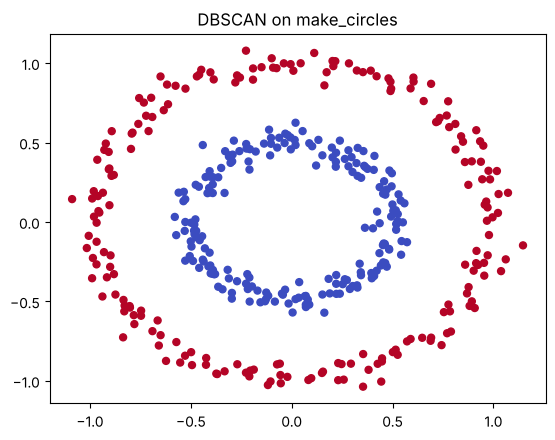

In [6]:
Xc, _ = make_circles(n_samples=400, factor=0.5, noise=0.05, random_state=RS)
lc = DBSCAN(eps=0.15, min_samples=5).fit_predict(Xc)
plt.scatter(Xc[:, 0], Xc[:, 1], c=lc, cmap="coolwarm", s=25)
plt.title("DBSCAN on make_circles"); plt.show()

### Q26. Load the Breast Cancer dataset, apply MinMaxScaler, and use K-Means with 2 clusters. Output the cluster centroids.

In [7]:
bc = load_breast_cancer()
Xbc = MinMaxScaler().fit_transform(bc.data)
km = KMeans(n_clusters=2, n_init=10, random_state=RS).fit(Xbc)
cent = pd.DataFrame(km.cluster_centers_, columns=bc.feature_names, index=["Cluster 0", "Cluster 1"])
print("Centroids (MinMax-scaled space), first 8 features:")
display(cent.iloc[:, :8].round(3))
print("Full centroid array shape:", km.cluster_centers_.shape)

Centroids (MinMax-scaled space), first 8 features:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points
Cluster 0,0.505,0.396,0.506,0.364,0.470,0.422,0.418,0.469
Cluster 1,0.255,0.288,0.247,0.144,0.357,0.180,0.103,0.131


Full centroid array shape: (2, 30)


### Q27. Generate synthetic data using make_blobs with varying cluster standard deviations and cluster with DBSCAN.

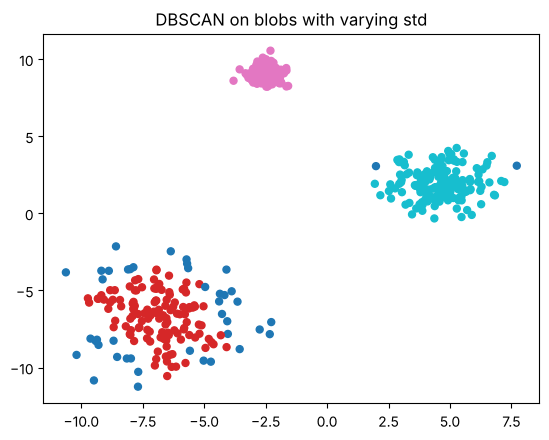

Clusters: 3 | Noise: 43


In [8]:
Xv, _ = make_blobs(n_samples=500, centers=3, cluster_std=[0.4, 1.0, 1.8], random_state=RS)
lv = DBSCAN(eps=0.7, min_samples=6).fit_predict(Xv)
plt.scatter(Xv[:, 0], Xv[:, 1], c=lv, cmap="tab10", s=25)
plt.title("DBSCAN on blobs with varying std"); plt.show()
print("Clusters:", len(set(lv)) - (1 if -1 in lv else 0), "| Noise:", (lv == -1).sum())

### Q28. Load the Digits dataset, reduce it to 2D using PCA, and visualize clusters from K-Means.

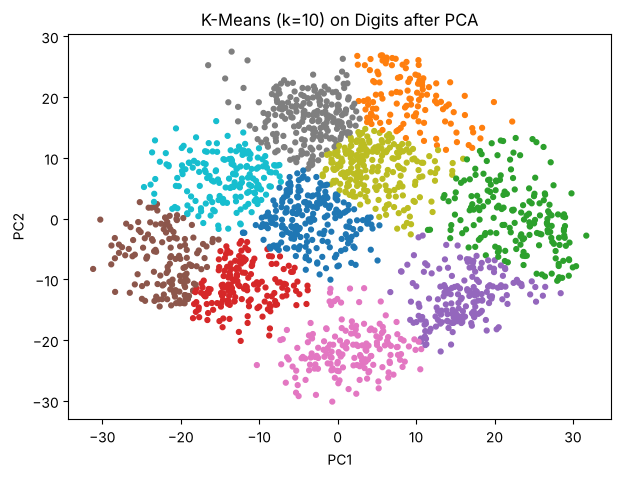

In [9]:
Xd = load_digits().data
Xd2 = PCA(n_components=2, random_state=RS).fit_transform(Xd)
ld = KMeans(n_clusters=10, n_init=10, random_state=RS).fit_predict(Xd2)
plt.figure(figsize=(7, 5))
plt.scatter(Xd2[:, 0], Xd2[:, 1], c=ld, cmap="tab10", s=12)
plt.title("K-Means (k=10) on Digits after PCA"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()

### Q29. Create synthetic data using make_blobs and evaluate silhouette scores for k = 2 to 5. Display as a bar chart.

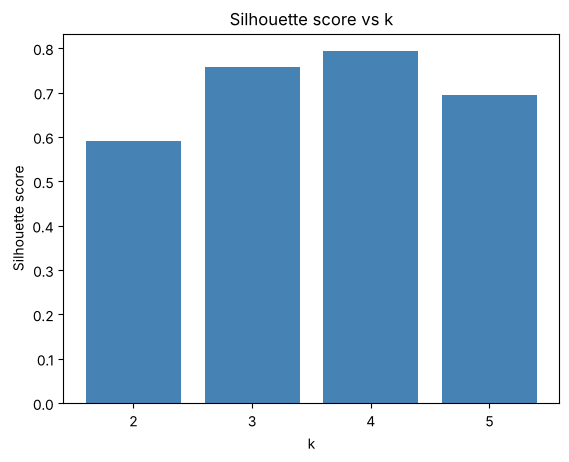

{2: np.float64(0.592), 3: np.float64(0.7575), 4: np.float64(0.7935), 5: np.float64(0.6949)}


In [10]:
Xs, _ = make_blobs(n_samples=400, centers=4, random_state=RS)
ks = range(2, 6)
sil = [silhouette_score(Xs, KMeans(n_clusters=k, n_init=10, random_state=RS).fit_predict(Xs)) for k in ks]
plt.bar([str(k) for k in ks], sil, color="steelblue")
plt.xlabel("k"); plt.ylabel("Silhouette score"); plt.title("Silhouette score vs k"); plt.show()
print(dict(zip(ks, np.round(sil, 4))))

### Q30. Load the Iris dataset and use hierarchical clustering to group data. Plot a dendrogram with average linkage.

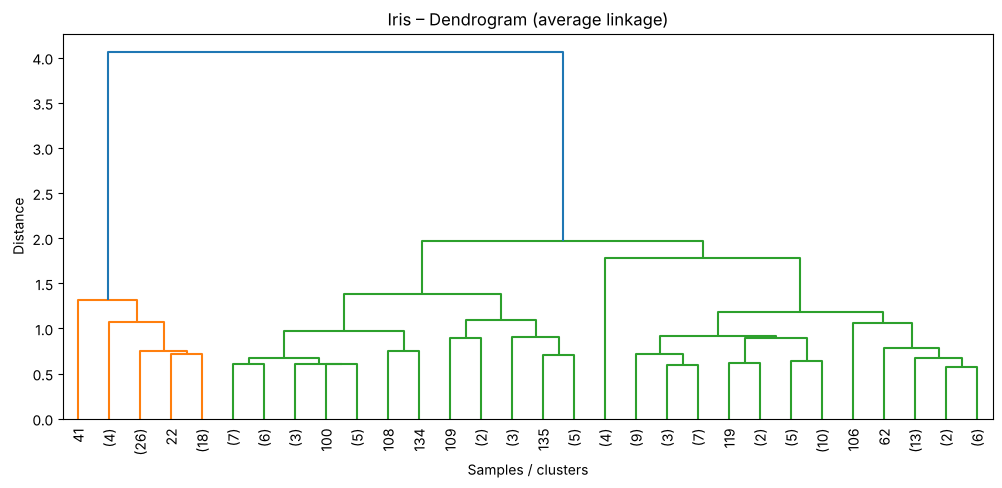

In [11]:
Z = linkage(load_iris().data, method="average")
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90)
plt.title("Iris – Dendrogram (average linkage)"); plt.xlabel("Samples / clusters"); plt.ylabel("Distance"); plt.show()

### Q31. Generate synthetic data with overlapping clusters using make_blobs, then apply K-Means and visualize with decision boundaries.

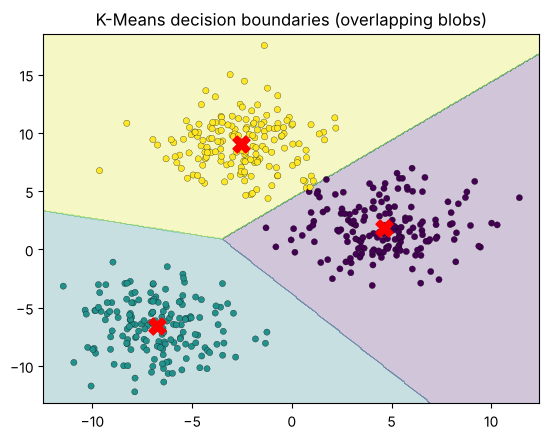

In [12]:
Xo, _ = make_blobs(n_samples=500, centers=3, cluster_std=2.2, random_state=RS)
kmo = KMeans(n_clusters=3, n_init=10, random_state=RS).fit(Xo)

xx, yy = np.meshgrid(np.linspace(Xo[:, 0].min() - 1, Xo[:, 0].max() + 1, 400),
                     np.linspace(Xo[:, 1].min() - 1, Xo[:, 1].max() + 1, 400))
Zb = kmo.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.contourf(xx, yy, Zb, alpha=0.25, cmap="viridis")
plt.scatter(Xo[:, 0], Xo[:, 1], c=kmo.labels_, cmap="viridis", s=20, edgecolor="k", linewidth=0.2)
plt.scatter(*kmo.cluster_centers_.T, c="red", marker="X", s=150)
plt.title("K-Means decision boundaries (overlapping blobs)"); plt.show()

### Q32. Load the Digits dataset and apply DBSCAN after reducing dimensions with t-SNE. Visualize the results.

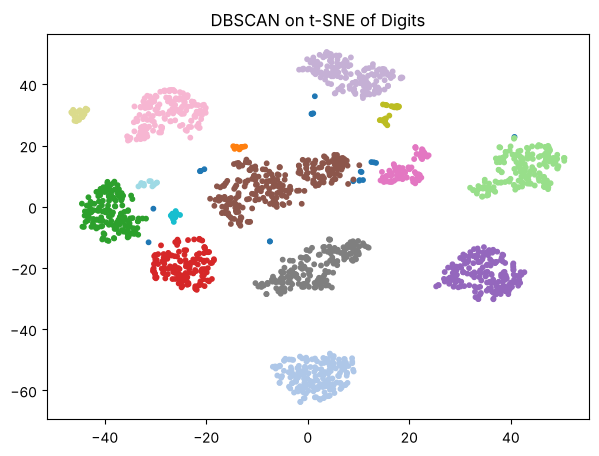

Clusters: 15 | Noise: 23


In [13]:
Xt = TSNE(n_components=2, random_state=RS, init="pca", perplexity=30).fit_transform(load_digits().data)
lt = DBSCAN(eps=3, min_samples=10).fit_predict(Xt)
plt.figure(figsize=(7, 5))
plt.scatter(Xt[:, 0], Xt[:, 1], c=lt, cmap="tab20", s=10)
plt.title("DBSCAN on t-SNE of Digits"); plt.show()
print("Clusters:", len(set(lt)) - (1 if -1 in lt else 0), "| Noise:", (lt == -1).sum())

### Q33. Generate synthetic data using make_blobs and apply Agglomerative Clustering with complete linkage. Plot the result.

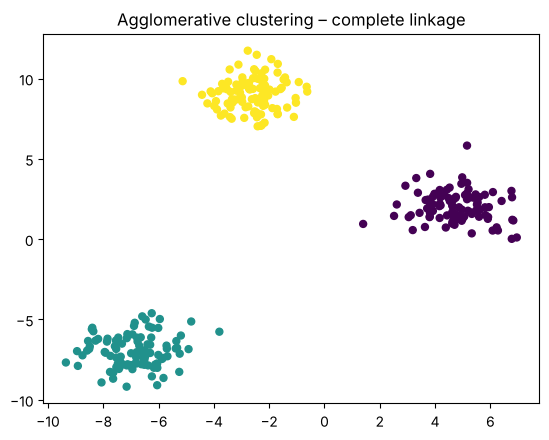

In [14]:
Xa, _ = make_blobs(n_samples=300, centers=3, random_state=RS)
la = AgglomerativeClustering(n_clusters=3, linkage="complete").fit_predict(Xa)
plt.scatter(Xa[:, 0], Xa[:, 1], c=la, cmap="viridis", s=25)
plt.title("Agglomerative clustering – complete linkage"); plt.show()

### Q34. Load the Breast Cancer dataset and compare inertia values for K = 2 to 6 using K-Means. Show results in a line plot.

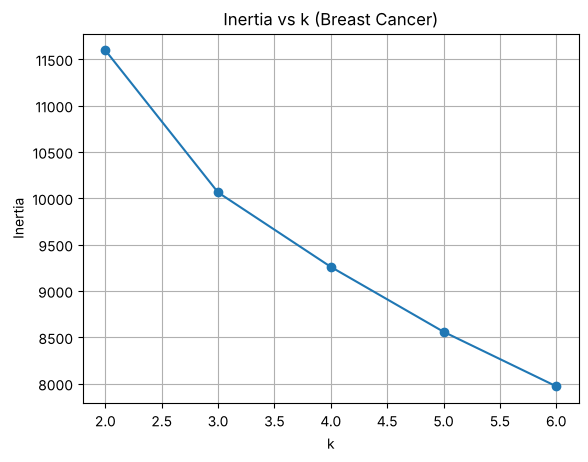

{2: np.float64(11595.5), 3: np.float64(10061.8), 4: np.float64(9259.0), 5: np.float64(8558.7), 6: np.float64(7970.3)}


In [15]:
Xb = StandardScaler().fit_transform(load_breast_cancer().data)
ks = range(2, 7)
inertias = [KMeans(n_clusters=k, n_init=10, random_state=RS).fit(Xb).inertia_ for k in ks]
plt.plot(list(ks), inertias, marker="o")
plt.xlabel("k"); plt.ylabel("Inertia"); plt.title("Inertia vs k (Breast Cancer)"); plt.grid(True); plt.show()
print(dict(zip(ks, np.round(inertias, 1))))

### Q35. Generate synthetic concentric circles using make_circles and cluster using Agglomerative Clustering with single linkage.

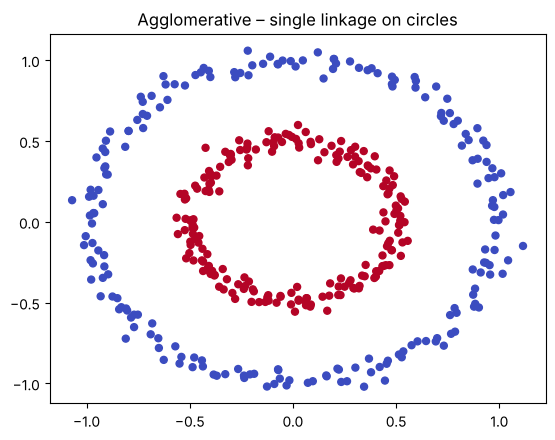

In [16]:
Xc2, _ = make_circles(n_samples=400, factor=0.5, noise=0.04, random_state=RS)
ls = AgglomerativeClustering(n_clusters=2, linkage="single").fit_predict(Xc2)
plt.scatter(Xc2[:, 0], Xc2[:, 1], c=ls, cmap="coolwarm", s=25)
plt.title("Agglomerative – single linkage on circles"); plt.show()

### Q36. Use the Wine dataset, apply DBSCAN after scaling the data, and count the number of clusters (excluding noise).

In [17]:
Xws = StandardScaler().fit_transform(load_wine().data)
lws = DBSCAN(eps=2.3, min_samples=5).fit_predict(Xws)
n_clusters = len(set(lws)) - (1 if -1 in lws else 0)
print("Number of clusters (excluding noise):", n_clusters)
print("Noise points:", (lws == -1).sum())

Number of clusters (excluding noise): 2
Noise points: 42


### Q37. Generate synthetic data with make_blobs and apply KMeans. Then plot the cluster centers on top of the data points.

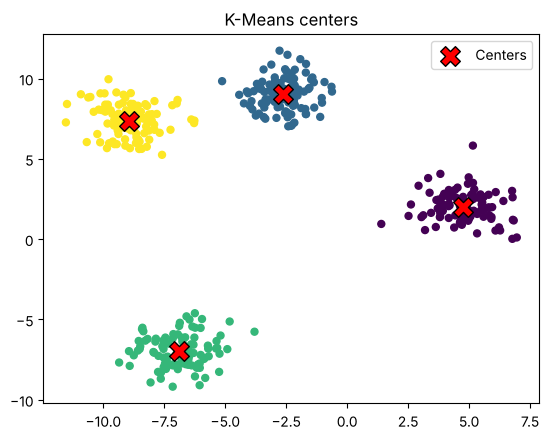

In [18]:
Xk, _ = make_blobs(n_samples=400, centers=4, random_state=RS)
kmk = KMeans(n_clusters=4, n_init=10, random_state=RS).fit(Xk)
plt.scatter(Xk[:, 0], Xk[:, 1], c=kmk.labels_, cmap="viridis", s=25)
plt.scatter(kmk.cluster_centers_[:, 0], kmk.cluster_centers_[:, 1], c="red", marker="X", s=200, edgecolor="k", label="Centers")
plt.legend(); plt.title("K-Means centers"); plt.show()

### Q38. Load the Iris dataset, cluster with DBSCAN, and print how many samples were identified as noise.

In [19]:
li = DBSCAN(eps=0.5, min_samples=5).fit_predict(load_iris().data)
print("Clusters found:", len(set(li)) - (1 if -1 in li else 0))
print("Noise samples :", (li == -1).sum())

Clusters found: 2
Noise samples : 17


### Q39. Generate synthetic non-linearly separable data using make_moons, apply K-Means, and visualize the clustering result.

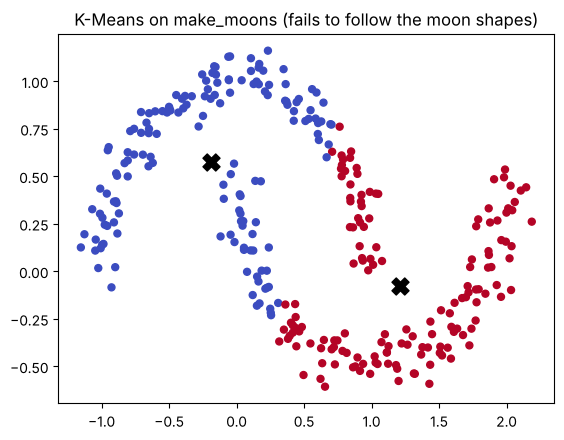

In [20]:
Xmm, _ = make_moons(n_samples=300, noise=0.07, random_state=RS)
kmm = KMeans(n_clusters=2, n_init=10, random_state=RS).fit(Xmm)
plt.scatter(Xmm[:, 0], Xmm[:, 1], c=kmm.labels_, cmap="coolwarm", s=25)
plt.scatter(*kmm.cluster_centers_.T, c="k", marker="X", s=150)
plt.title("K-Means on make_moons (fails to follow the moon shapes)"); plt.show()

### Q40. Load the Digits dataset, apply PCA to reduce to 3 components, then use KMeans and visualize with a 3D scatter plot.

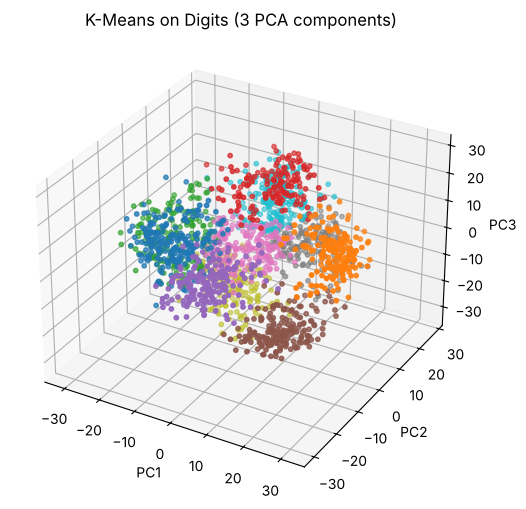

In [21]:
X3 = PCA(n_components=3, random_state=RS).fit_transform(load_digits().data)
l3 = KMeans(n_clusters=10, n_init=10, random_state=RS).fit_predict(X3)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X3[:, 0], X3[:, 1], X3[:, 2], c=l3, cmap="tab10", s=10)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3")
ax.set_title("K-Means on Digits (3 PCA components)"); plt.show()

### Q41. Generate synthetic blobs with 5 centers and apply KMeans. Then use silhouette_score to evaluate the clustering.

In [22]:
X5, _ = make_blobs(n_samples=500, centers=5, random_state=RS)
l5 = KMeans(n_clusters=5, n_init=10, random_state=RS).fit_predict(X5)
print("Silhouette score:", round(silhouette_score(X5, l5), 4))

Silhouette score: 0.6786


### Q42. Load the Breast Cancer dataset, reduce dimensionality using PCA, and apply Agglomerative Clustering. Visualize in 2D.

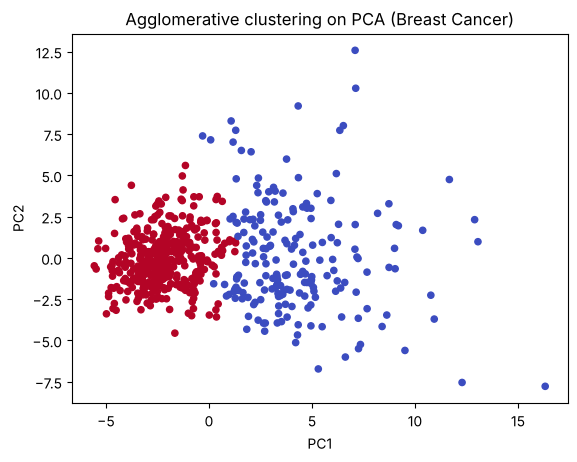

In [23]:
Xp = PCA(n_components=2, random_state=RS).fit_transform(StandardScaler().fit_transform(load_breast_cancer().data))
lp = AgglomerativeClustering(n_clusters=2).fit_predict(Xp)
plt.scatter(Xp[:, 0], Xp[:, 1], c=lp, cmap="coolwarm", s=20)
plt.title("Agglomerative clustering on PCA (Breast Cancer)"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()

### Q43. Generate noisy circular data using make_circles and visualize clustering results from KMeans and DBSCAN side-by-side.

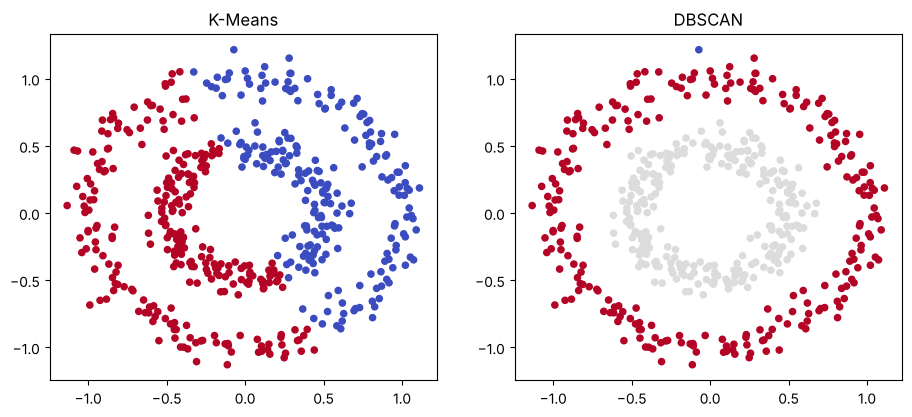

In [24]:
Xn, _ = make_circles(n_samples=500, factor=0.5, noise=0.07, random_state=RS)
lk = KMeans(n_clusters=2, n_init=10, random_state=RS).fit_predict(Xn)
ld2 = DBSCAN(eps=0.15, min_samples=5).fit_predict(Xn)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(Xn[:, 0], Xn[:, 1], c=lk, cmap="coolwarm", s=20); axes[0].set_title("K-Means")
axes[1].scatter(Xn[:, 0], Xn[:, 1], c=ld2, cmap="coolwarm", s=20); axes[1].set_title("DBSCAN")
plt.show()

### Q44. Load the Iris dataset and plot the Silhouette Coefficient for each sample after KMeans clustering.

Average silhouette: 0.5528


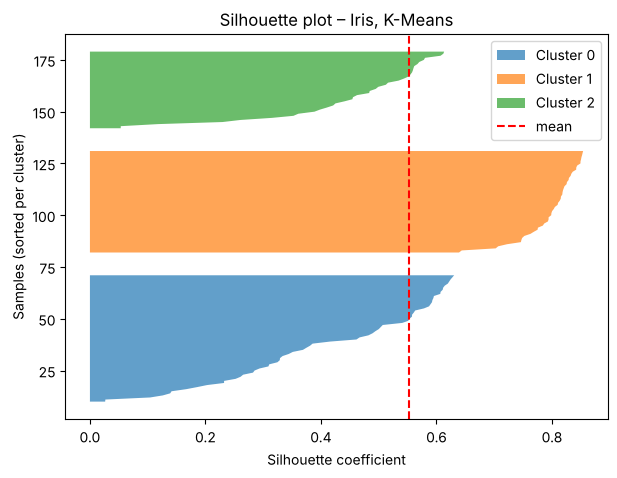

In [25]:
Xis = load_iris().data
lis = KMeans(n_clusters=3, n_init=10, random_state=RS).fit_predict(Xis)
sv = silhouette_samples(Xis, lis)
print("Average silhouette:", round(sv.mean(), 4))

fig, ax = plt.subplots(figsize=(7, 5))
y_low = 10
for c in range(3):
    cs = np.sort(sv[lis == c])
    ax.fill_betweenx(np.arange(y_low, y_low + len(cs)), 0, cs, alpha=0.7, label=f"Cluster {c}")
    y_low += len(cs) + 10
ax.axvline(sv.mean(), color="red", linestyle="--", label="mean")
ax.set_xlabel("Silhouette coefficient"); ax.set_ylabel("Samples (sorted per cluster)")
ax.set_title("Silhouette plot – Iris, K-Means"); ax.legend(); plt.show()

### Q45. Generate synthetic data using make_blobs and apply Agglomerative Clustering with 'average' linkage. Visualize clusters.

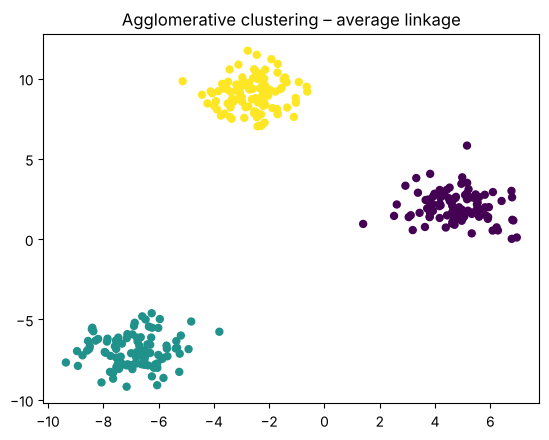

In [26]:
Xav, _ = make_blobs(n_samples=300, centers=3, random_state=RS)
lav = AgglomerativeClustering(n_clusters=3, linkage="average").fit_predict(Xav)
plt.scatter(Xav[:, 0], Xav[:, 1], c=lav, cmap="viridis", s=25)
plt.title("Agglomerative clustering – average linkage"); plt.show()

### Q46. Load the Wine dataset, apply KMeans, and visualize the cluster assignments in a seaborn pairplot (first 4 features).

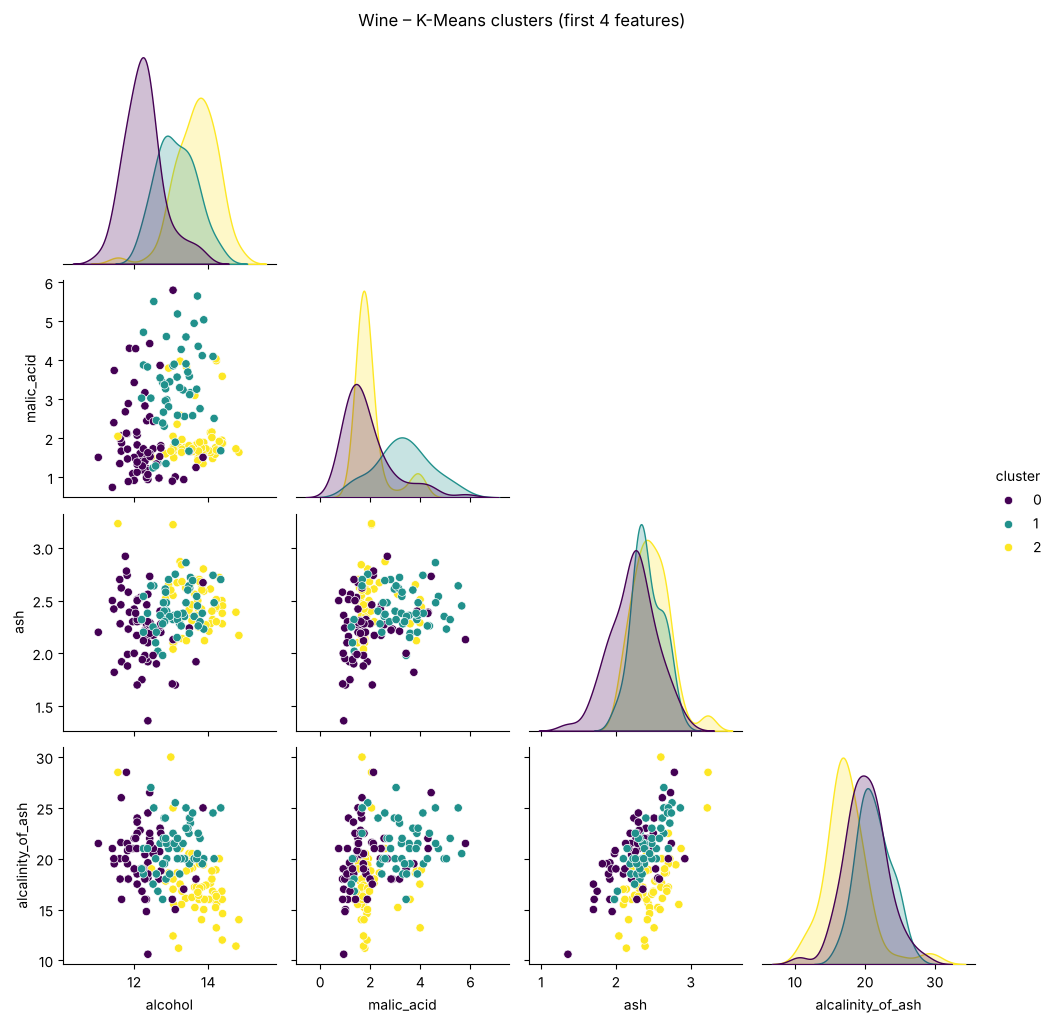

In [27]:
wine = load_wine(as_frame=True)
dfw = wine.data.iloc[:, :4].copy()
dfw["cluster"] = KMeans(n_clusters=3, n_init=10, random_state=RS).fit_predict(StandardScaler().fit_transform(wine.data))
sns.pairplot(dfw, hue="cluster", palette="viridis", corner=True)
plt.suptitle("Wine – K-Means clusters (first 4 features)", y=1.02); plt.show()

### Q47. Generate noisy blobs using make_blobs and use DBSCAN to identify both clusters and noise points. Print the count.

Clusters found: 3
Noise points  : 39


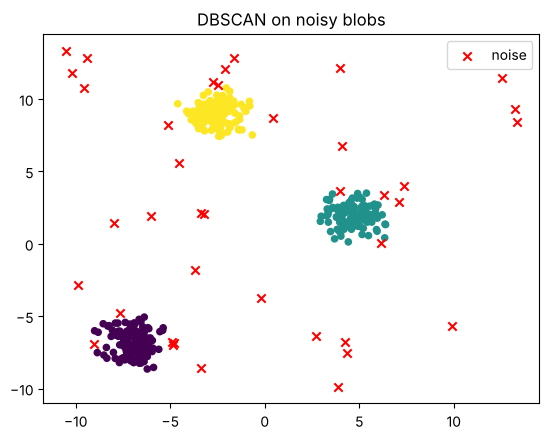

In [28]:
Xnb, _ = make_blobs(n_samples=400, centers=3, cluster_std=0.8, random_state=RS)
rng = np.random.RandomState(RS)
Xnb = np.vstack([Xnb, rng.uniform(Xnb.min() - 2, Xnb.max() + 2, size=(30, 2))])  # add random noise

lnb = DBSCAN(eps=0.7, min_samples=6).fit_predict(Xnb)
print("Clusters found:", len(set(lnb)) - (1 if -1 in lnb else 0))
print("Noise points  :", (lnb == -1).sum())

plt.scatter(Xnb[lnb != -1, 0], Xnb[lnb != -1, 1], c=lnb[lnb != -1], cmap="viridis", s=20)
plt.scatter(Xnb[lnb == -1, 0], Xnb[lnb == -1, 1], c="red", marker="x", label="noise")
plt.legend(); plt.title("DBSCAN on noisy blobs"); plt.show()

### Q48. Load the Digits dataset, reduce dimensions using t-SNE, then apply Agglomerative Clustering and plot the clusters.

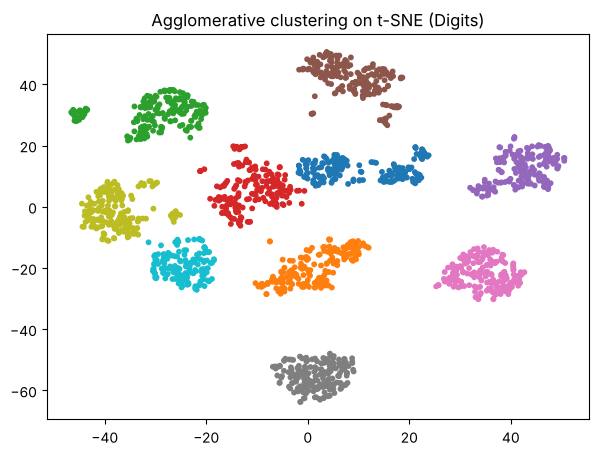

In [29]:
Xts = TSNE(n_components=2, random_state=RS, init="pca").fit_transform(load_digits().data)
lts = AgglomerativeClustering(n_clusters=10, linkage="ward").fit_predict(Xts)
plt.figure(figsize=(7, 5))
plt.scatter(Xts[:, 0], Xts[:, 1], c=lts, cmap="tab10", s=10)
plt.title("Agglomerative clustering on t-SNE (Digits)"); plt.show()

---
**End of assignment.**